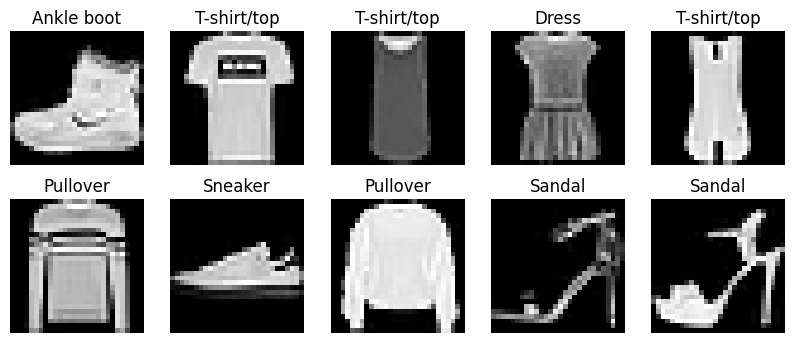

In [7]:
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Load data
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
class_names = ['T-shirt/top','Trouser','Pullover','Dress','Coat',
               'Sandal','Shirt','Sneaker','Bag','Ankle boot']

# Preprocess
x_train = x_train[..., None] / 255.0
x_test  = x_test[..., None] / 255.0

# Look at samples
plt.figure(figsize=(10,4))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.title(class_names[y_train[i]]); plt.axis('off')
plt.show()

In [3]:
model = models.Sequential([
    layers.Input((28,28,1)),
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu', padding='same'),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

cb = tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)
history = model.fit(x_train, y_train, epochs=20, batch_size=128,
                    validation_split=0.1, callbacks=[cb])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,346 (368.54 KB)

 Trainable params: 94,154 (367.79 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.7554 - loss: 0.6802 - val_accuracy: 0.1077 - val_loss: 3.7079
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8597 - loss: 0.3976 - val_accuracy: 0.8702 - val_loss: 0.3615
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8814 - loss: 0.3370 - val_accuracy: 0.8892 - val_loss: 0.3086
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8922 - loss: 0.3022 - val_accuracy: 0.8485 - val_loss: 0.4337
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9002 - loss: 0.2795 - val_accuracy: 0.8900 - val_loss: 0.2900
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9072 - loss: 0.2591 - val_accuracy: 0.9072 - val_loss: 0.2614
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9127 - loss: 0.2459 - val_accuracy: 0.9157 - val_loss: 0.2369
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9185 - loss: 0.2325 - val_accuracy: 

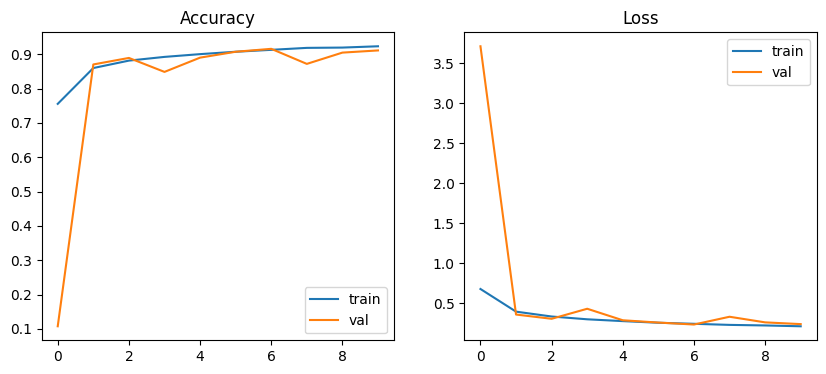

313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9038 - loss: 0.2686
Test accuracy: 0.9038000106811523
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
              precision    recall  f1-score   support

 T-shirt/top       0.84      0.87      0.86      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.83      0.90      0.86      1000
       Dress       0.95      0.84      0.89      1000
        Coat       0.81      0.88      0.84      1000
      Sandal       0.98      0.97      0.98      1000
       Shirt       0.75      0.68      0.71      1000
     Sneaker       0.97      0.95      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.95      0.98      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



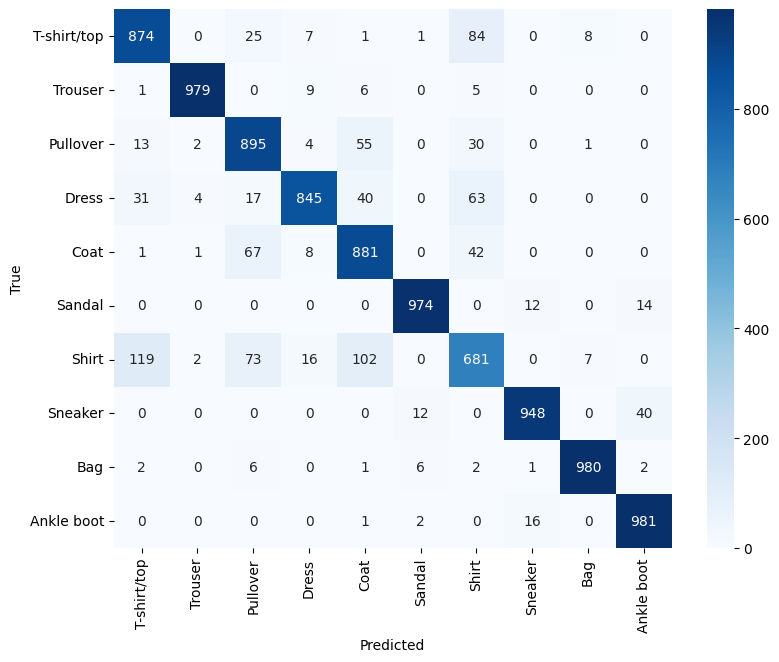

In [4]:
# Training curves
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val'); plt.legend(); plt.title('Accuracy')
plt.subplot(1,2,2); plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val'); plt.legend(); plt.title('Loss')
plt.show()

# Evaluate
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Test accuracy:", test_acc)

y_pred = np.argmax(model.predict(x_test), axis=1)
print(classification_report(y_test, y_pred, target_names=class_names))

plt.figure(figsize=(9,7))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d',
            xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.show()

# Save model
model.save('fashion_cnn.keras')

In [5]:
import time, pandas as pd

def build_dense():
    return models.Sequential([
        layers.Input((28,28,1)),
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])

def build_cnn():
    return models.Sequential([
        layers.Input((28,28,1)),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation='relu', padding='same'),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.4),
        layers.Dense(10, activation='softmax')
    ])

def train_model(model):
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    cb = tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)
    start = time.time()
    hist = model.fit(x_train, y_train, epochs=20, batch_size=128,
                     validation_split=0.1, callbacks=[cb], verbose=2)
    return hist, time.time() - start

dense_model = build_dense()
cnn_model = build_cnn()

dense_hist, dense_time = train_model(dense_model)
cnn_hist, cnn_time = train_model(cnn_model)

Epoch 1/20
422/422 - 8s - 18ms/step - accuracy: 0.7934 - loss: 0.5802 - val_accuracy: 0.8465 - val_loss: 0.4150
Epoch 2/20
422/422 - 1s - 3ms/step - accuracy: 0.8490 - loss: 0.4180 - val_accuracy: 0.8628 - val_loss: 0.3747
Epoch 3/20
422/422 - 1s - 3ms/step - accuracy: 0.8626 - loss: 0.3779 - val_accuracy: 0.8728 - val_loss: 0.3507
Epoch 4/20
422/422 - 1s - 3ms/step - accuracy: 0.8721 - loss: 0.3508 - val_accuracy: 0.8742 - val_loss: 0.3480
Epoch 5/20
422/422 - 2s - 4ms/step - accuracy: 0.8746 - loss: 0.3405 - val_accuracy: 0.8752 - val_loss: 0.3362
Epoch 6/20
422/422 - 1s - 3ms/step - accuracy: 0.8796 - loss: 0.3265 - val_accuracy: 0.8767 - val_loss: 0.3363
Epoch 7/20
422/422 - 1s - 3ms/step - accuracy: 0.8843 - loss: 0.3143 - val_accuracy: 0.8790 - val_loss: 0.3317
Epoch 8/20
422/422 - 1s - 3ms/step - accuracy: 0.8861 - loss: 0.3056 - val_accuracy: 0.8812 - val_loss: 0.3180
Epoch 9/20
422/422 - 1s - 3ms/step - accuracy: 0.8916 - loss: 0.2944 - val_accuracy: 0.8837 - val_loss: 0.3180


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
           Model  Accuracy  Precision  Recall  F1-Score  Training Time (s)  Parameters
Dense (Baseline)    0.8784     0.8801  0.8784    0.8780               25.8      235146
             CNN    0.9106     0.9097  0.9106    0.9095               46.1       94346


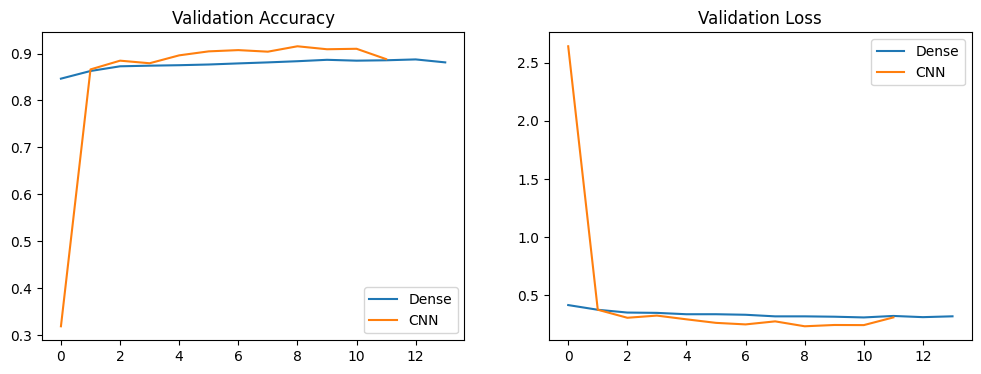

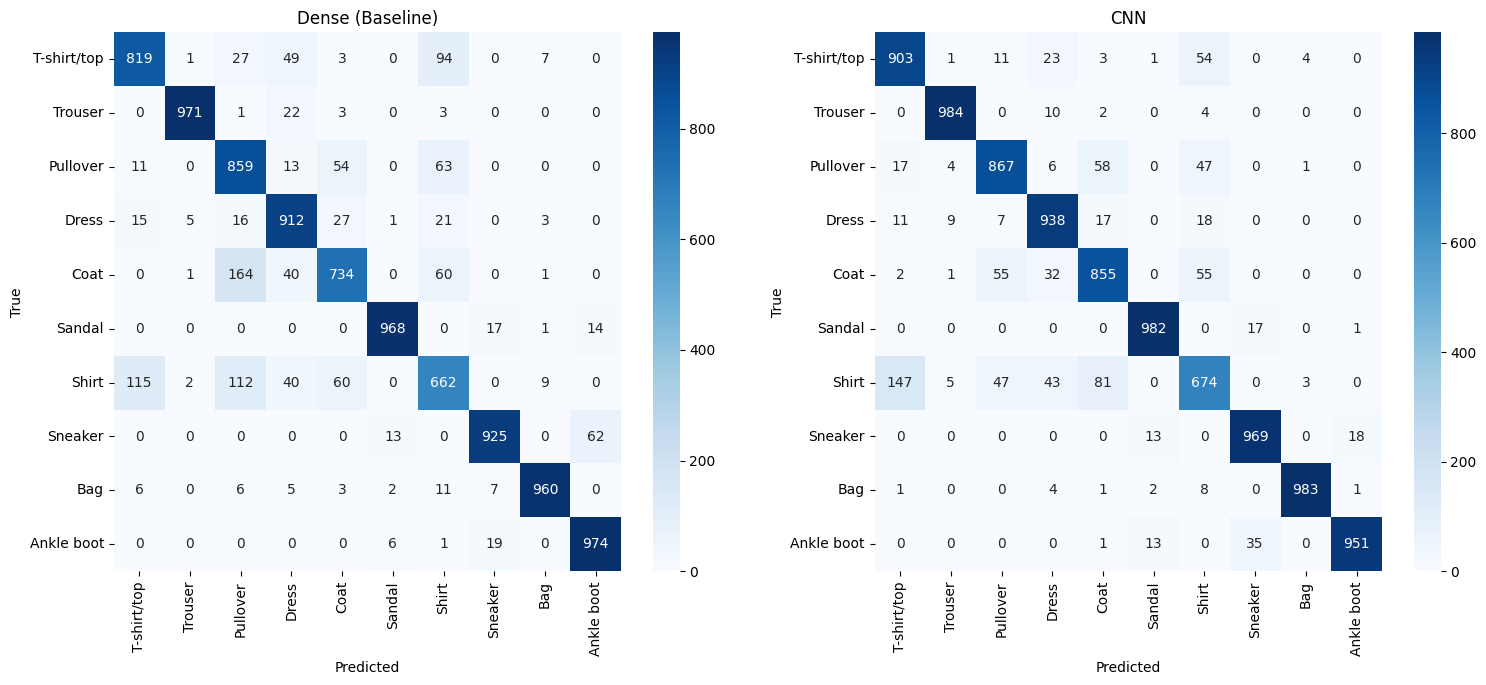

In [6]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

rows = []
preds = {}
for name, m, t in [("Dense (Baseline)", dense_model, dense_time),
                   ("CNN", cnn_model, cnn_time)]:
    y_pred = np.argmax(m.predict(x_test), axis=1)
    preds[name] = y_pred
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
    rows.append({"Model": name,
                 "Accuracy": round(accuracy_score(y_test, y_pred), 4),
                 "Precision": round(p, 4),
                 "Recall": round(r, 4),
                 "F1-Score": round(f, 4),
                 "Training Time (s)": round(t, 1),
                 "Parameters": m.count_params()})

results = pd.DataFrame(rows)
print(results.to_string(index=False))

# Accuracy and loss graphs
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in [("Dense", dense_hist), ("CNN", cnn_hist)]:
    ax[0].plot(h.history['val_accuracy'], label=name)
    ax[1].plot(h.history['val_loss'], label=name)
ax[0].set_title('Validation Accuracy'); ax[0].legend()
ax[1].set_title('Validation Loss'); ax[1].legend()
plt.show()

# Confusion matrices
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for a, (name, y_pred) in zip(ax, preds.items()):
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d',
                cmap='Blues', xticklabels=class_names,
                yticklabels=class_names, ax=a)
    a.set_title(name); a.set_xlabel('Predicted'); a.set_ylabel('True')
plt.show()